# Bayesian regression for NYC apartment asking rents

### Clean the October 2026 listings

The target is `price`, the monthly asking rent before concessions.

The features are borough, neighborhood, building type, bedrooms, full bathrooms, half bathrooms, furnished status, and new-development status.

In [10]:
import csv
from pathlib import Path

DATA_PATH = Path("2026-Oct-nyc-rental-listings.csv")
NYC_BOROUGHS = ("Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island")
CATEGORICAL_FEATURES = (
    "borough", "neighborhood", "building_type", "furnished", "is_new_development"
)
# square footage is 0 for ~77% of NYC listings, so we will not include it as a feature to retain those rows
NUMERIC_FEATURES = ("bedrooms", "bathrooms", "half_baths")
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "price"

with DATA_PATH.open(encoding="utf-8-sig", newline="") as file:
    raw_listings = list(csv.DictReader(file))

nyc_listings = [
    row for row in raw_listings
    if row["state"].strip() == "NY" and row["borough"].strip() in NYC_BOROUGHS
]

Treat `UNKNOWN` building type as missing. Keep zero bedrooms for studios and zero half baths. Exclude listings with more than 8 full baths or more than 5 half baths as a data cleaning rule for this sample (since such values are likely errors). There were values such as 720 half baths and 25 full baths that should not be included.

In [11]:
clean_listings = []
for row in nyc_listings:
    if row["building_type"] == "UNKNOWN":
        continue

    listing = row.copy()
    for field in (*NUMERIC_FEATURES, TARGET):
        listing[field] = int(row[field])

    if listing["bathrooms"] > 8 or listing["half_baths"] > 5:
        continue

    clean_listings.append(listing)

In [12]:
print(f"Rows in the CSV: {len(raw_listings):,}")
print(f"NYC rows before cleaning: {len(nyc_listings):,}")
print(f"NYC rows after cleaning: {len(clean_listings):,}")

Rows in the CSV: 15,794
NYC rows before cleaning: 13,812
NYC rows after cleaning: 13,791


### Deduplicate listings

Keep the newest cleaned record for each listing URL using `created_at_utc`.

In [13]:
listings_by_date = sorted(clean_listings, key=lambda row: row["created_at_utc"])
latest_by_url = {row["url"]: row for row in listings_by_date}
deduplicated_listings = list(latest_by_url.values())

print(f"Rows removed by repeated listing URL: {len(clean_listings) - len(deduplicated_listings):,}")
print(f"Rows after deduplication: {len(deduplicated_listings):,}")

Rows removed by repeated listing URL: 78
Rows after deduplication: 13,713


### Train/test split

An address group includes all listings with the same borough and street address, ignoring capitalization and extra spaces. For example, apartments 2A and 5B at the same Brooklyn address belong to one group.

We hold out 20% of address groups using seed 42. Each group goes entirely into either training or testing, so the test set measures how well the model predicts rent at addresses it hasn't seen during training.

Use `train_listing_ids` and `test_listing_ids` to match these rows in the MLP.

In [14]:
from collections import Counter

from sklearn.model_selection import GroupShuffleSplit


address_groups = [
    row["borough"].strip().casefold() + "|" + " ".join(row["street"].casefold().split())
    for row in deduplicated_listings
]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_indices, test_indices = next(splitter.split(deduplicated_listings, groups=address_groups))

train_listings = [deduplicated_listings[index] for index in train_indices]
test_listings = [deduplicated_listings[index] for index in test_indices]
train_listing_ids = [row["id"] for row in train_listings]
test_listing_ids = [row["id"] for row in test_listings]

train_addresses = {address_groups[index] for index in train_indices}
test_addresses = {address_groups[index] for index in test_indices}
shared_addresses = train_addresses & test_addresses
assert not shared_addresses, "An address appears in both splits."

print(f"Training rows: {len(train_listings):,} across {len(train_addresses):,} address groups")
print(f"Test rows: {len(test_listings):,} across {len(test_addresses):,} address groups")
print(f"Address groups in both splits: {len(shared_addresses)}")

train_by_borough = Counter(row["borough"] for row in train_listings)
test_by_borough = Counter(row["borough"] for row in test_listings)
print()
print(f"{'Borough':<15} {'Train':>7} {'Test':>7}")
for borough in NYC_BOROUGHS:
    print(f"{borough:<15} {train_by_borough[borough]:>7,} {test_by_borough[borough]:>7,}")

Training rows: 10,952 across 5,959 address groups
Test rows: 2,761 across 1,490 address groups
Address groups in both splits: 0

Borough           Train    Test
Bronx               310     128
Brooklyn          4,474   1,179
Manhattan         4,388     997
Queens            1,763     453
Staten Island        17       4


### Bayesian ridge regression

Fit the preprocessing and model on the training listings. Standardize the numeric features and one-hot encode the categorical features. A category that first appears at prediction time gets zeros in that feature's indicator columns.

Bayesian ridge estimates a linear relationship with log asking rent and shrinks coefficients toward zero. The model gives a predicted mean and standard deviation on the log scale. For a normal log-rent prediction with mean $\mu$ and standard deviation $\sigma$, the expected rent in dollars is $\exp(\mu + \sigma^2/2)$. The 90% prediction interval comes from converting the 5th and 95th percentiles to dollars.

In [15]:
from statistics import NormalDist

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.preprocessing import OneHotEncoder, StandardScaler


train_frame = pd.DataFrame(train_listings)
X_train = train_frame[list(FEATURES)]
y_train = train_frame[TARGET].to_numpy()

# turn categorical features into 0/1 columns and standardize numeric features
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), list(NUMERIC_FEATURES)),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(CATEGORICAL_FEATURES)),
])
X_train_encoded = preprocessor.fit_transform(X_train)

bayesian_model = BayesianRidge()
bayesian_model.fit(X_train_encoded, np.log(y_train))

,"max_iter max_iter: int, default=300Maximum number of iterations over the complete dataset beforestopping independently of any early stopping criterion... versionchanged:: 1.3",300
,"tol tol: float, default=1e-3Stop the algorithm if w has converged.",0.001
,"alpha_1 alpha_1: float, default=1e-6Hyper-parameter : shape parameter for the Gamma distribution priorover the alpha parameter.",1e-06
,"alpha_2 alpha_2: float, default=1e-6Hyper-parameter : inverse scale parameter (rate parameter) for theGamma distribution prior over the alpha parameter.",1e-06
,"lambda_1 lambda_1: float, default=1e-6Hyper-parameter : shape parameter for the Gamma distribution priorover the lambda parameter.",1e-06
,"lambda_2 lambda_2: float, default=1e-6Hyper-parameter : inverse scale parameter (rate parameter) for theGamma distribution prior over the lambda parameter.",1e-06
,"alpha_init alpha_init: float, default=NoneInitial value for alpha (precision of the noise).If not set, alpha_init is 1/Var(y)... versionadded:: 0.22",None
,"lambda_init lambda_init: float, default=NoneInitial value for lambda (precision of the weights).If not set, lambda_init is 1... versionadded:: 0.22",None
,"compute_score compute_score: bool, default=FalseIf True, compute the log marginal likelihood at each iteration of theoptimization.",False
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model.The intercept is not treated as a probabilistic parameterand thus has no associated variance. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True


In [16]:
def predict_rent(encoded_features):
    log_mean, log_std = bayesian_model.predict(encoded_features, return_std=True)
    z_90 = NormalDist().inv_cdf(0.95)
    expected_rent = np.exp(log_mean + log_std**2 / 2)
    lower = np.exp(log_mean - z_90 * log_std)
    upper = np.exp(log_mean + z_90 * log_std)
    return expected_rent, lower, upper


train_predictions, train_lower, train_upper = predict_rent(X_train_encoded)
train_coverage = np.mean((train_lower <= y_train) & (y_train <= train_upper))

print(f"Encoded features: {X_train_encoded.shape[1]:,}")
print(f"Model fit iterations: {bayesian_model.n_iter_}")
print(f"Training MAE: ${mean_absolute_error(y_train, train_predictions):,.2f}")
print(f"Training RMSE: ${root_mean_squared_error(y_train, train_predictions):,.2f}")
print(f"Training coverage of the 90% prediction interval: {train_coverage:.1%}")

Encoded features: 233
Model fit iterations: 5
Training MAE: $755.49
Training RMSE: $1,206.48
Training coverage of the 90% prediction interval: 91.5%


### Evaluate on test addresses

The baseline predicts the median training rent for every test listing. Compare the two models in dollars using mean absolute error (MAE) and root mean squared error (RMSE), plus $R^2$. MAE is the primary metric. The test set measures performance on new addresses within October 2026. Use these same test listings to compare with the MLP.

In [17]:
from IPython.display import display


X_test = pd.DataFrame(test_listings)[list(FEATURES)]
y_test = np.array([row[TARGET] for row in test_listings])
X_test_encoded = preprocessor.transform(X_test)
test_predictions, test_lower, test_upper = predict_rent(X_test_encoded)
baseline_predictions = np.full(y_test.shape, np.median(y_train))

assert np.isfinite([test_predictions, test_lower, test_upper]).all()
assert np.all(test_lower <= test_upper)

predictions_by_model = {
    "Bayesian ridge": test_predictions,
    "Training median baseline": baseline_predictions,
}
test_results = pd.DataFrame.from_dict(
    {
        name: {
            "MAE ($)": mean_absolute_error(y_test, predictions),
            "RMSE ($)": root_mean_squared_error(y_test, predictions),
            "R²": r2_score(y_test, predictions),
        }
        for name, predictions in predictions_by_model.items()
    },
    orient="index",
)

test_coverage = np.mean((test_lower <= y_test) & (y_test <= test_upper))
print(f"Test listings: {len(y_test):,}")
display(test_results.rename_axis("Model").style.format({
    "MAE ($)": "{:,.2f}",
    "RMSE ($)": "{:,.2f}",
    "R²": "{:.3f}",
}))
print(f"Test coverage of the 90% prediction interval: {test_coverage:.1%}")

Test listings: 2,761


,MAE ($),RMSE ($),R²
Model,,,
Bayesian ridge,756.04,"1,246.59",0.728
Training median baseline,"1,567.70","2,469.49",-0.067


Test coverage of the 90% prediction interval: 92.4%


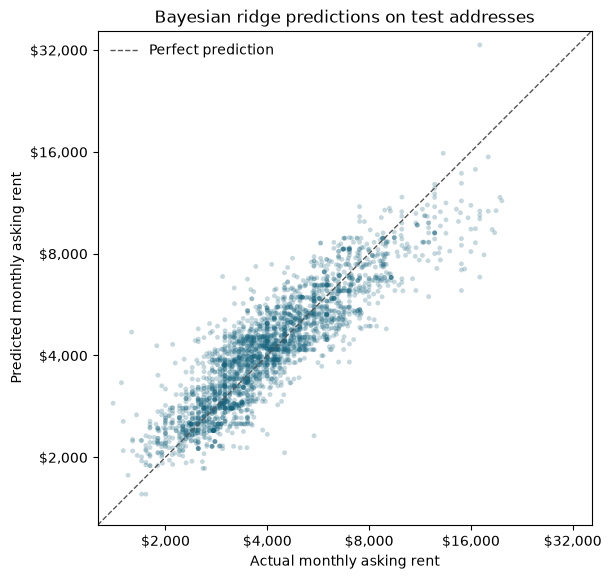

In [18]:
%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


lower = 0.9 * min(y_test.min(), test_predictions.min())
upper = 1.1 * max(y_test.max(), test_predictions.max())
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
ax.scatter(y_test, test_predictions, s=12, alpha=0.25, color="#17647e", edgecolors="none")
ax.plot([lower, upper], [lower, upper], "--", color="#555555", linewidth=1, label="Perfect prediction")
ax.set(
    title="Bayesian ridge predictions on test addresses",
    xlabel="Actual monthly asking rent",
    ylabel="Predicted monthly asking rent",
    xscale="log",
    yscale="log",
    xlim=(lower, upper),
    ylim=(lower, upper),
    aspect="equal",
)
ticks = [rent for rent in (500, 1_000, 2_000, 4_000, 8_000, 16_000, 32_000, 64_000) if lower <= rent <= upper]
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.minorticks_off()
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend(loc="upper left", frameon=False)
plt.show()